In [6]:
import os
import string
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.14.0+cpu
CUDA available: False


In [7]:
#Load the emnist dataset
data_dir="./data"

transform=transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,),(0.5,))
])

train_dataset=datasets.EMNIST(
    root=data_dir,
    split="letters",
    train=True,
    download=True,
    transform=transform,
    target_transform=lambda y:y-1)

test_dataset=datasets.EMNIST(
    root=data_dir,
    split="letters",
    train=False,
    download=True,
    transform=transform,
    target_transform=lambda y:y-1
)
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Number of classes:", 26)

Training images: 124800
Testing images: 20800
Number of classes: 26


In [8]:
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)
print("Image loaded successfully!")

Image shape: torch.Size([1, 28, 28])
Label: 22
Image loaded successfully!


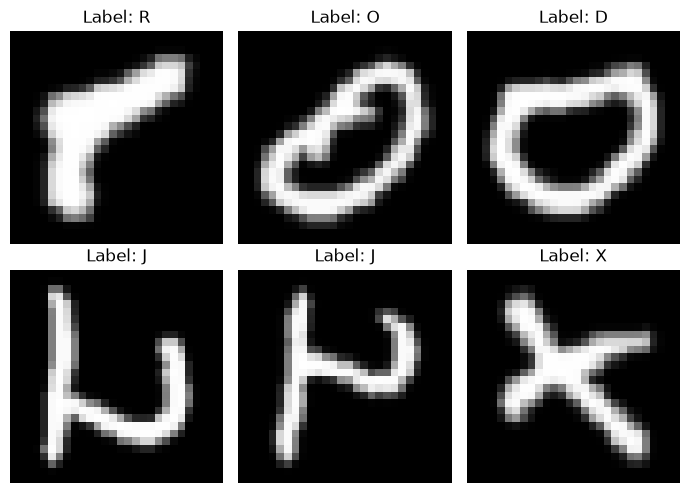

In [10]:
#Visualize Handwritten Letters

letters=string.ascii_uppercase
fig,axes=plt.subplots(2,3,figsize=(7,5))
for ax,index in zip(axes.flat,random.sample(
    range(len(train_dataset)),6
)):
    image, label = train_dataset[index]

    # Display the image upright
    ax.imshow(image.squeeze().numpy(), cmap="gray")
    ax.set_title(f"Label: {letters[label]}")
    ax.axis("off")

plt.tight_layout()
plt.show()
plt.close(fig)

In [11]:
image,label=train_dataset[0]
print("Image shape:",image.shape)
print("Label Index:",label)
print("Corresponding letter:", letters[label])
print("Pixel minimum:", image.min().item())
print("Pixel maximum:", image.max().item())

Image shape: torch.Size([1, 28, 28])
Label Index: 22
Corresponding letter: W
Pixel minimum: -1.0
Pixel maximum: 1.0


In [12]:
batch_size=128
train_loader=DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

test_loader=DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)
images, labels = next(iter(train_loader))

print("Batch images:", images.shape)
print("Batch labels:", labels.shape)

Batch images: torch.Size([128, 1, 28, 28])
Batch labels: torch.Size([128])


In [14]:
class AlphabetCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features=nn.Sequential(
            nn.Conv2d(1,32,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32,64,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 26)
        )

    def forward(self,x):
        x=self.features(x)
        x=self.classifier(x)
        return x

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

model=AlphabetCNN().to(device)
print(model)
print("Device:", device)
print(
    "Total parameters:",
    sum(p.numel() for p in model.parameters())
)

AlphabetCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=26, bias=True)
  )
)
Device: cpu
Total parameters: 423706


In [15]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)

Loss function: CrossEntropyLoss()
Optimizer: Adam


In [16]:
from pathlib import Path
import string
import torch

EPOCHS = 5
best_val_acc = 0.0

best_model_path = Path("models/alphabet_cnn_best.pth")
best_model_path.parent.mkdir(parents=True, exist_ok=True)

class_names = list(string.ascii_uppercase)

train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

for epoch in range(EPOCHS):

    # -------------------------
    # TRAINING
    # -------------------------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_train_loss = running_loss / total
    epoch_train_acc = correct / total

    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)

    # -------------------------
    # VALIDATION
    # -------------------------
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    epoch_val_loss = val_running_loss / val_total
    epoch_val_acc = val_correct / val_total

    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)

    # -------------------------
    # SAVE BEST MODEL
    # -------------------------
    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_accuracy": best_val_acc,
            "class_names": class_names,
            "num_classes": 26,
            "image_size": 28
        }, best_model_path)

        saved_message = " | Best model saved!"
    else:
        saved_message = ""

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Train Acc: {epoch_train_acc:.2%} | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Val Acc: {epoch_val_acc:.2%}"
        f"{saved_message}"
    )

print(f"\nBest validation accuracy: {best_val_acc:.2%}")
print(f"Best model saved at: {best_model_path.resolve()}")

Epoch [1/5] Train Loss: 0.6348 | Train Acc: 80.33% | Val Loss: 0.2828 | Val Acc: 90.57% | Best model saved!
Epoch [2/5] Train Loss: 0.3221 | Train Acc: 89.62% | Val Loss: 0.2274 | Val Acc: 92.64% | Best model saved!
Epoch [3/5] Train Loss: 0.2699 | Train Acc: 91.22% | Val Loss: 0.2187 | Val Acc: 92.89% | Best model saved!
Epoch [4/5] Train Loss: 0.2388 | Train Acc: 92.02% | Val Loss: 0.1979 | Val Acc: 93.62% | Best model saved!
Epoch [5/5] Train Loss: 0.2168 | Train Acc: 92.67% | Val Loss: 0.1989 | Val Acc: 93.65% | Best model saved!

Best validation accuracy: 93.65%
Best model saved at: C:\Users\PRAWIN KUMAR\EnglishAlphabetRecognition\models\alphabet_cnn_best.pth


In [17]:
import torch
import string

checkpoint = torch.load(
    "models/alphabet_cnn_best.pth",
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

letters = string.ascii_uppercase

print("Best epoch:", checkpoint["epoch"])
print(f"Saved validation accuracy: {checkpoint['val_accuracy']:.2%}")
print("Number of classes:", checkpoint["num_classes"])
print("Model loaded successfully!")

Best epoch: 5
Saved validation accuracy: 93.65%
Number of classes: 26
Model loaded successfully!


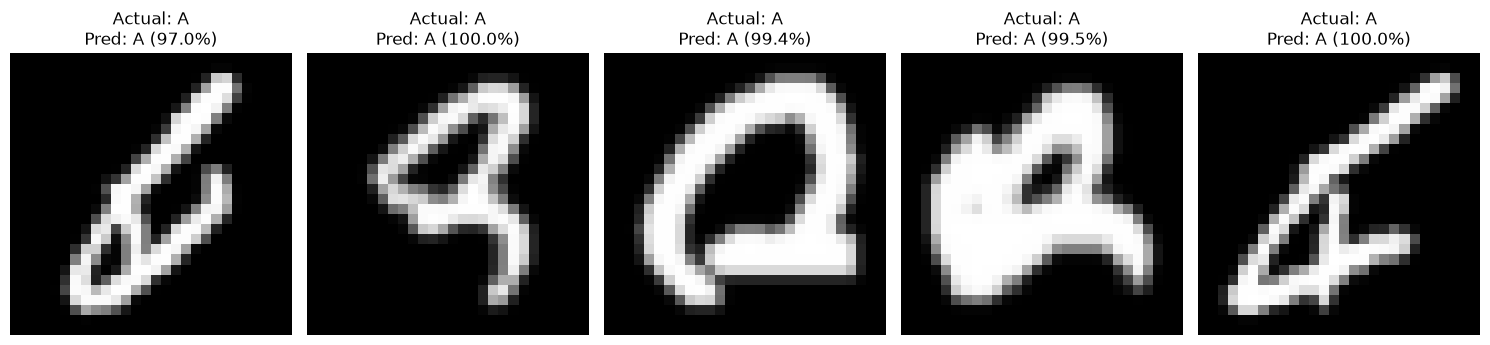

In [19]:
import matplotlib.pyplot as plt
import torch

fig, axes = plt.subplots(1, 5, figsize=(15, 4))

model.eval()

for i, ax in enumerate(axes):
    image, actual_label = test_dataset[i + 10]

    with torch.no_grad():
        logits = model(image.unsqueeze(0).to(device))
        probabilities = torch.softmax(logits, dim=1)[0]

        predicted_label = probabilities.argmax().item()
        confidence = probabilities[predicted_label].item() * 100

    ax.imshow(image.squeeze().numpy(), cmap="gray")
    ax.set_title(
        f"Actual: {letters[actual_label]}\n"
        f"Pred: {letters[predicted_label]} ({confidence:.1f}%)"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [32]:
def preprocess_letter(image_path):
    image = cv2.imread(image_path)

    if image is None:
        raise ValueError("Could not read image. Check the file path.")

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Threshold: dark strokes become white
    _, binary = cv2.threshold(
        gray, 0, 255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    contours, _ = cv2.findContours(
        binary,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    if not contours:
        raise ValueError("No handwritten letter detected.")

    # Select the largest contour
    contour = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(contour)

    character = binary[y:y+h, x:x+w]

    # Resize while preserving aspect ratio
    target_size = 20
    scale = target_size / max(w, h)

    new_w = max(1, int(w * scale))
    new_h = max(1, int(h * scale))

    resized = cv2.resize(
        character,
        (new_w, new_h),
        interpolation=cv2.INTER_AREA
    )

    # Center on a black 28x28 canvas
    canvas = np.zeros((28, 28), dtype=np.uint8)

    x_offset = (28 - new_w) // 2
    y_offset = (28 - new_h) // 2

    canvas[
        y_offset:y_offset + new_h,
        x_offset:x_offset + new_w
    ] = resized

    # Correct orientation for this model's input convention
    canvas = cv2.transpose(canvas)

    return canvas

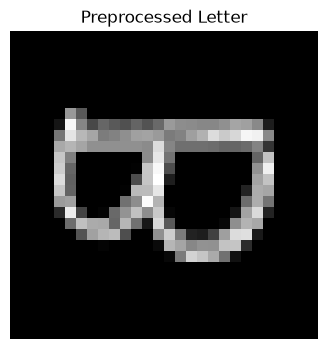

Processed image shape: (28, 28)


In [33]:
image_path = (r"D:\photos\test_img.jpg")

processed = preprocess_letter(image_path)

plt.figure(figsize=(4, 4))
plt.imshow(processed, cmap="gray")
plt.title("Preprocessed Letter")
plt.axis("off")
plt.show()

print("Processed image shape:", processed.shape)

In [34]:
import torch

def predict_letter(image_path):
    processed = preprocess_letter(image_path)

    # Convert to float and normalize from [0, 255]
    # to [-1, 1], matching the training transform.
    image_array = processed.astype(np.float32) / 255.0
    image_array = (image_array - 0.5) / 0.5

    # Shape: [batch, channel, height, width]
    tensor = torch.from_numpy(image_array).unsqueeze(0).unsqueeze(0)
    tensor = tensor.to(device)

    model.eval()

    with torch.no_grad():
        outputs = model(tensor)
        probabilities = torch.softmax(outputs, dim=1)[0]

        predicted_index = probabilities.argmax().item()
        confidence = probabilities[predicted_index].item() * 100

    predicted_letter = string.ascii_uppercase[predicted_index]

    plt.figure(figsize=(4, 4))
    plt.imshow(processed, cmap="gray")
    plt.title(f"Prediction: {predicted_letter} ({confidence:.2f}%)")
    plt.axis("off")
    plt.show()

    print("Predicted letter:", predicted_letter)
    print(f"Confidence: {confidence:.2f}%")

    return predicted_letter, confidence

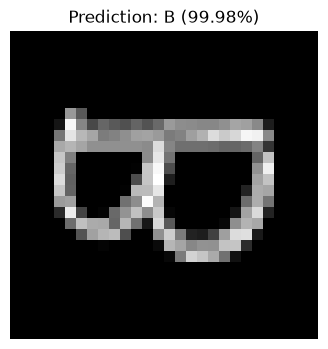

Predicted letter: B
Confidence: 99.98%


('B', 99.9798834323883)

In [35]:
predict_letter("D:\\photos\\test_img.jpg")